<a href="https://colab.research.google.com/github/k-v-n25/ML-AI/blob/main/AIML_LAB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
from google.colab import drive

drive.mount('/content/drive')
file_path = '/content/drive/My Drive/SEM 5/AIML LAB/Prediction_Data.csv'

df = pd.read_csv(file_path)

print("Step1: Loading Dataset from Google Drive")
print(df.info())

Mounted at /content/drive
Step1: Loading Dataset from Google Drive
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB
None


In [ ]:
rows = df.shape[0]
cols = df.shape[1]
print(f"Total Rows: {rows}")
print(f"Total Columns: {cols}")
print("-"*40)

print("Data Types for Each Column:")
print(df.dtypes)
print("-"*40)

print("Missing Values per Column: ")
print(df.isnull().sum())

Total Rows: 614
Total Columns: 13
----------------------------------------
Data Types for Each Column:
Loan_ID               object
Gender                object
Married               object
Dependents            object
Education             object
Self_Employed         object
ApplicantIncome        int64
CoapplicantIncome    float64
LoanAmount           float64
Loan_Amount_Term     float64
Credit_History       float64
Property_Area         object
Loan_Status           object
dtype: object
----------------------------------------
Missing Values per Column: 
Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64


In [ ]:
print("First 5 Records")
display(df.head(5))
print("-" * 50)

print("Last 5 Records ")
display(df.tail(5))
print("-" * 50)

print(" 5 Randomly Selected Records ")
display(df.sample(5, random_state=42))

First 5 Records


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


--------------------------------------------------
Last 5 Records 


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y
613,LP002990,Female,No,0,Graduate,Yes,4583,0.0,133.0,360.0,0.0,Semiurban,N


--------------------------------------------------
 5 Randomly Selected Records 


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
350,LP002139,Male,Yes,0,Graduate,No,9083,0.0,228.0,360.0,1.0,Semiurban,Y
377,LP002223,Male,Yes,0,Graduate,No,4310,0.0,130.0,360.0,NaN,Semiurban,Y
163,LP001570,Male,Yes,2,Graduate,No,4167,1447.0,158.0,360.0,1.0,Rural,Y
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
132,LP001478,Male,No,0,Graduate,No,2718,0.0,70.0,360.0,1.0,Semiurban,Y


In [ ]:
categorical_cols = ['Gender', 'Married', 'Dependents', 'Self_Employed', 'Credit_History']

for col in categorical_cols:
    most_frequent_value = df[col].mode()[0]
    df[col] = df[col].fillna(most_frequent_value)

numerical_cols_with_nan = ['LoanAmount', 'Loan_Amount_Term']

for col in numerical_cols_with_nan:
    robust_middle_value = df[col].median()
    df[col] = df[col].fillna(robust_middle_value)

print("Missing values remaining in the dataset:")
print(df.isnull().sum())

Missing values remaining in the dataset:
Loan_ID              0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64


In [ ]:
duplicate_count = df.duplicated().sum()
print(f"Duplicate rows found: {duplicate_count}")

if duplicate_count > 0:
    df = df.drop_duplicates()

Duplicate rows found: 0


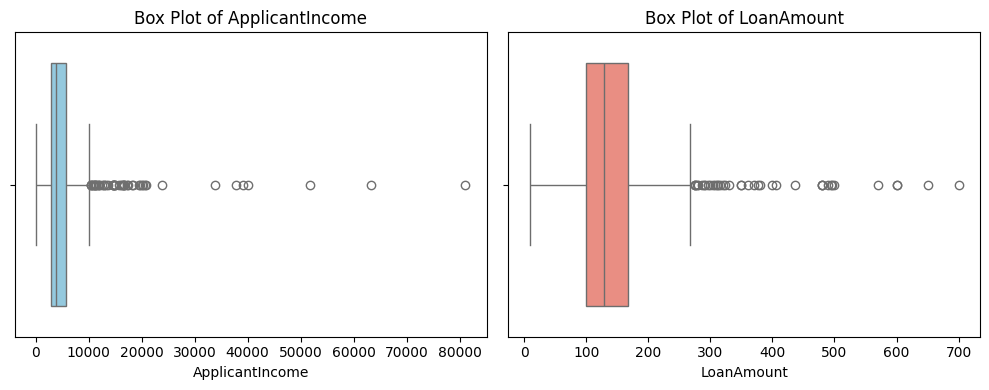

ApplicantIncome - Number of Outliers: 50
LoanAmount - Number of Outliers: 39


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
sns.boxplot(data=df, x='ApplicantIncome', color='skyblue')
plt.title('Box Plot of ApplicantIncome')

plt.subplot(1, 2, 2)
sns.boxplot(data=df, x='LoanAmount', color='salmon')
plt.title('Box Plot of LoanAmount')

plt.tight_layout()
plt.show()

for col in ['ApplicantIncome', 'LoanAmount']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    print(f"{col} - Number of Outliers: {len(outliers)}")

#7

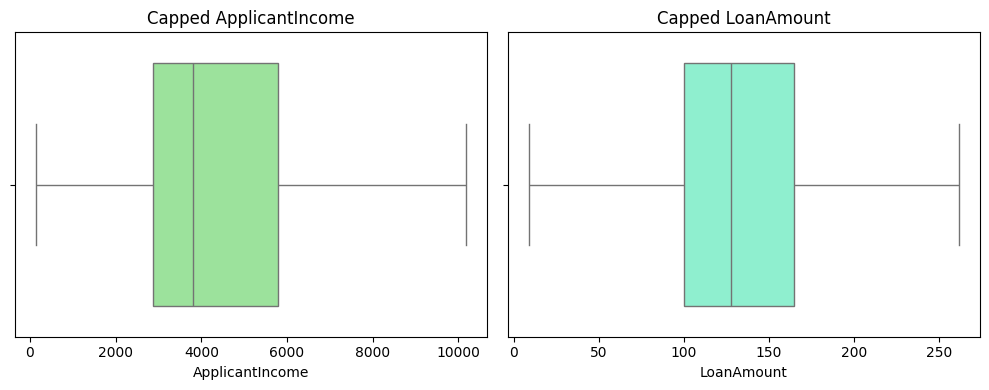

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

for col in ['ApplicantIncome', 'LoanAmount']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df[col] = np.where(df[col] > upper_bound, upper_bound,
                       np.where(df[col] < lower_bound, lower_bound, df[col]))

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
sns.boxplot(data=df, x='ApplicantIncome', color='lightgreen')
plt.title('Capped ApplicantIncome')

plt.subplot(1, 2, 2)
sns.boxplot(data=df, x='LoanAmount', color='aquamarine')
plt.title('Capped LoanAmount')
plt.tight_layout()
plt.show()

9

In [ ]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

scaler_minmax = MinMaxScaler()
df['ApplicantIncome_MinMax'] = scaler_minmax.fit_transform(df[['ApplicantIncome']])

scaler_std = StandardScaler()
df['ApplicantIncome_Std'] = scaler_std.fit_transform(df[['ApplicantIncome']])

display(df[['ApplicantIncome', 'ApplicantIncome_MinMax', 'ApplicantIncome_Std']].head(5))

df = df.drop(columns=['ApplicantIncome_MinMax', 'ApplicantIncome_Std'])

,ApplicantIncome,ApplicantIncome_MinMax,ApplicantIncome_Std
0,5849.0,0.568692,0.497164
1,4583.0,0.442360,-0.013767
2,3000.0,0.284396,-0.652632
3,2583.0,0.242784,-0.820924
4,6000.0,0.583760,0.558104


10


In [ ]:
from sklearn.preprocessing import LabelEncoder

df_encoded = df.copy()

if 'Loan_ID' in df_encoded.columns:
    df_encoded = df_encoded.drop(columns=['Loan_ID'])

le = LabelEncoder()
for col in ['Gender', 'Married', 'Education', 'Self_Employed', 'Loan_Status']:
    if col in df_encoded.columns:
        df_encoded[col] = le.fit_transform(df_encoded[col])

df_encoded = pd.get_dummies(df_encoded, columns=['Dependents', 'Property_Area'], drop_first=True)
df_encoded = df_encoded.astype({col: 'int64' for col in df_encoded.select_dtypes(include='bool').columns})

correlation_with_target = df_encoded.corr()['Loan_Status'].sort_values(ascending=False)

print("Correlation of all features with Loan_Status:")
print(correlation_with_target)

threshold = 0.05
relevant_features = correlation_with_target[abs(correlation_with_target) > threshold].index.tolist()
relevant_features.remove('Loan_Status')

print("\nSelected relevant features based on correlation threshold (> 0.05):")
print(relevant_features)

Correlation of all features with Loan_Status:
Loan_Status                1.000000
Credit_History             0.540556
Property_Area_Semiurban    0.136540
Married                    0.091478
Dependents_2               0.062384
Gender                     0.017987
ApplicantIncome           -0.000442
Self_Employed             -0.003700
Loan_Amount_Term          -0.022549
Dependents_3+             -0.026123
Dependents_1              -0.038740
Property_Area_Urban       -0.043621
LoanAmount                -0.047262
CoapplicantIncome         -0.059187
Education                 -0.085884
Name: Loan_Status, dtype: float64

Selected relevant features based on correlation threshold (> 0.05):
['Credit_History', 'Property_Area_Semiurban', 'Married', 'Dependents_2', 'CoapplicantIncome', 'Education']


11

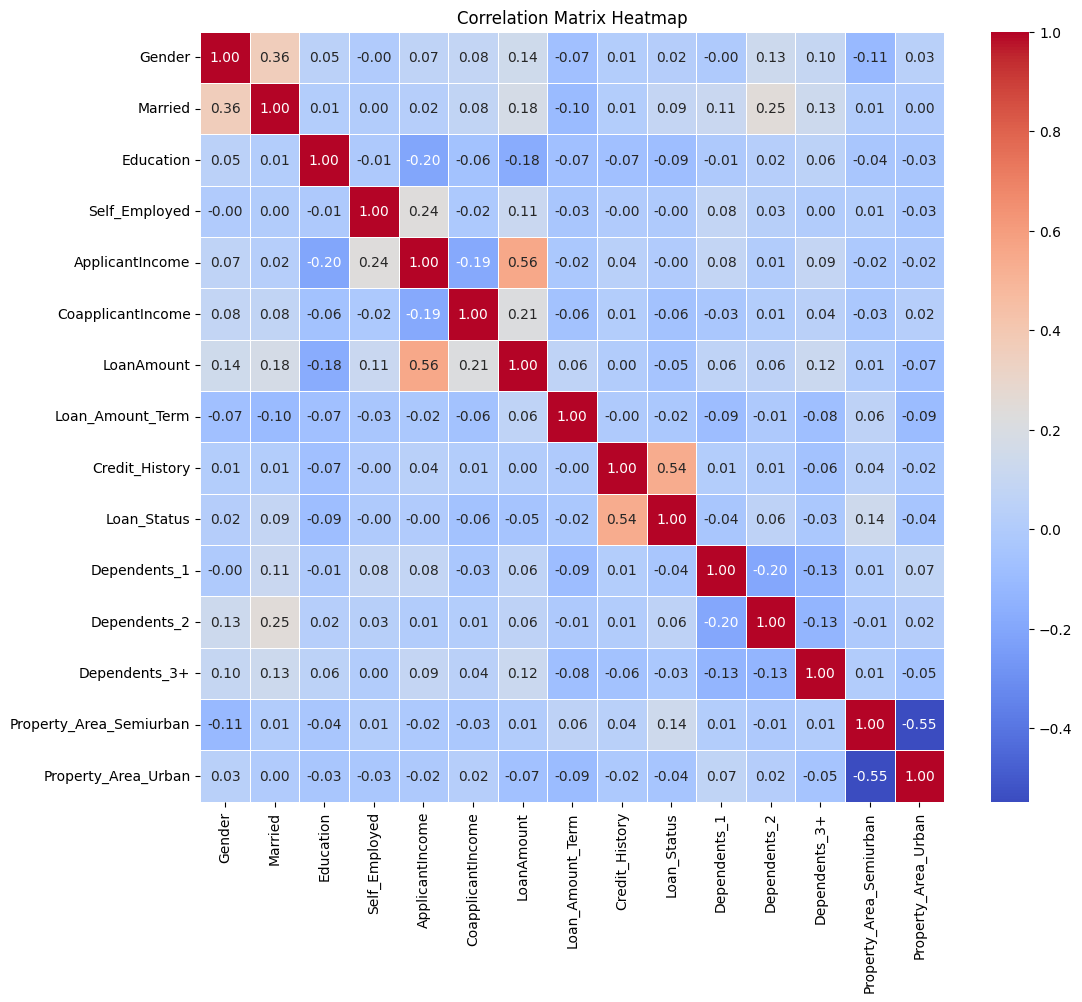

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder

df_encoded = df.copy()

if 'Loan_ID' in df_encoded.columns:
    df_encoded = df_encoded.drop(columns=['Loan_ID'])

le = LabelEncoder()
for col in ['Gender', 'Married', 'Education', 'Self_Employed', 'Loan_Status']:
    if col in df_encoded.columns:
        df_encoded[col] = le.fit_transform(df_encoded[col])

df_encoded = pd.get_dummies(df_encoded, columns=['Dependents', 'Property_Area'], drop_first=True)
df_encoded = df_encoded.astype({col: 'int64' for col in df_encoded.select_dtypes(include='bool').columns})

plt.figure(figsize=(12, 10))
corr_matrix = df_encoded.corr()

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Matrix Heatmap')
plt.show()

In [ ]:
import pandas as pd
from google.colab import drive

# 1. Mount Drive and load the dataset to define 'df'
drive.mount('/content/drive')
file_path = '/content/drive/My Drive/SEM 5/AIML LAB/Prediction_Data.csv'
df = pd.read_csv(file_path)

# 2. Handle missing values for Credit_History first so the conversion doesn't fail
df['Credit_History'] = df['Credit_History'].fillna(df['Credit_History'].mode()[0])

# 3. Convert Credit_History from float (1.0, 0.0) to integer (1, 0)
df['Credit_History'] = df['Credit_History'].astype('int64')

# 4. Convert ApplicantIncome from integer to float for uniform precision
df['ApplicantIncome'] = df['ApplicantIncome'].astype('float64')

# 5. Verify the new data types
print("Updated Data Types:")
print(df[['Credit_History', 'ApplicantIncome']].dtypes)

Mounted at /content/drive
Updated Data Types:
Credit_History       int64
ApplicantIncome    float64
dtype: object


### 14

In [ ]:
# 1. Clean inconsistent formatting in the 'Dependents' column (e.g., stripping '+' symbols)
df['Dependents'] = df['Dependents'].astype(str).str.replace('+', '', regex=False)

# 2. Convert the column to numeric, forcing any remaining unparseable noise to NaN
df['Dependents'] = pd.to_numeric(df['Dependents'], errors='coerce')

# 3. Fill any newly created NaNs with the column median
df['Dependents'] = df['Dependents'].fillna(df['Dependents'].median()).astype(int)

# 4. Remove white spaces from all text/categorical columns to fix hidden formatting errors
categorical_cols = df.select_dtypes(include=['object']).columns
for col in categorical_cols:
    df[col] = df[col].astype(str).str.strip()

print("Unique values in 'Dependents' after cleaning noise:", df['Dependents'].unique())

Unique values in 'Dependents' after cleaning noise: [0 1 2 3]


#15

In [ ]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['Loan_Status'])
y = df['Loan_Status']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"Training Features Shape (X_train): {X_train.shape}")
print(f"Testing Features Shape (X_test): {X_test.shape}")
print(f"Training Target Shape (y_train): {y_train.shape}")
print(f"Testing Target Shape (y_test): {y_test.shape}")

Training Features Shape (X_train): (491, 12)
Testing Features Shape (X_test): (123, 12)
Training Target Shape (y_train): (491,)
Testing Target Shape (y_test): (123,)


#17

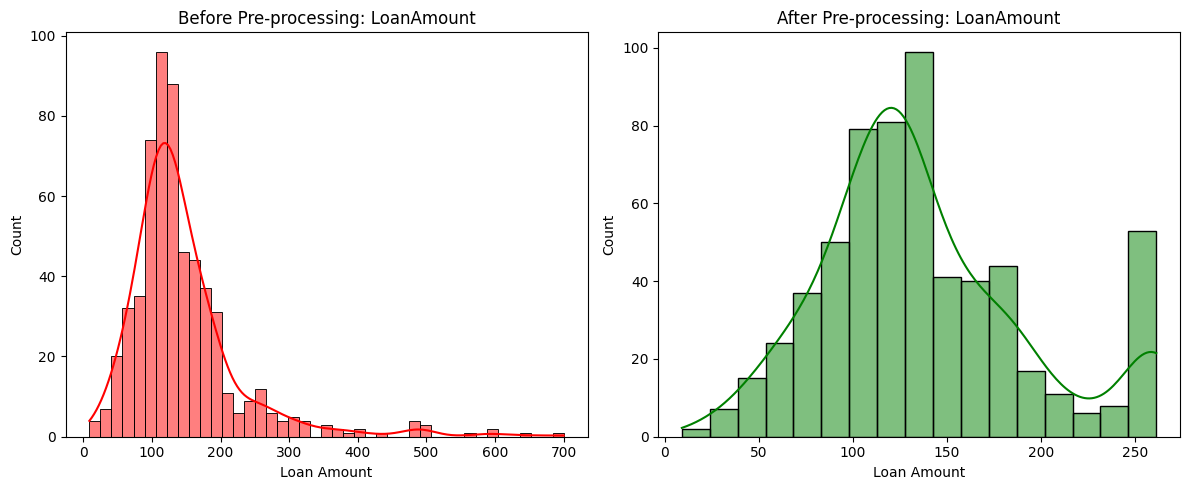

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

df_raw = pd.read_csv('/content/drive/My Drive/SEM 5/AIML LAB/Prediction_Data.csv')

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(df_raw['LoanAmount'].dropna(), kde=True, color='red', ax=axes[0])
axes[0].set_title('Before Pre-processing: LoanAmount')
axes[0].set_xlabel('Loan Amount')

sns.histplot(df['LoanAmount'], kde=True, color='green', ax=axes[1])
axes[1].set_title('After Pre-processing: LoanAmount')
axes[1].set_xlabel('Loan Amount')

plt.tight_layout()
plt.show()

#18


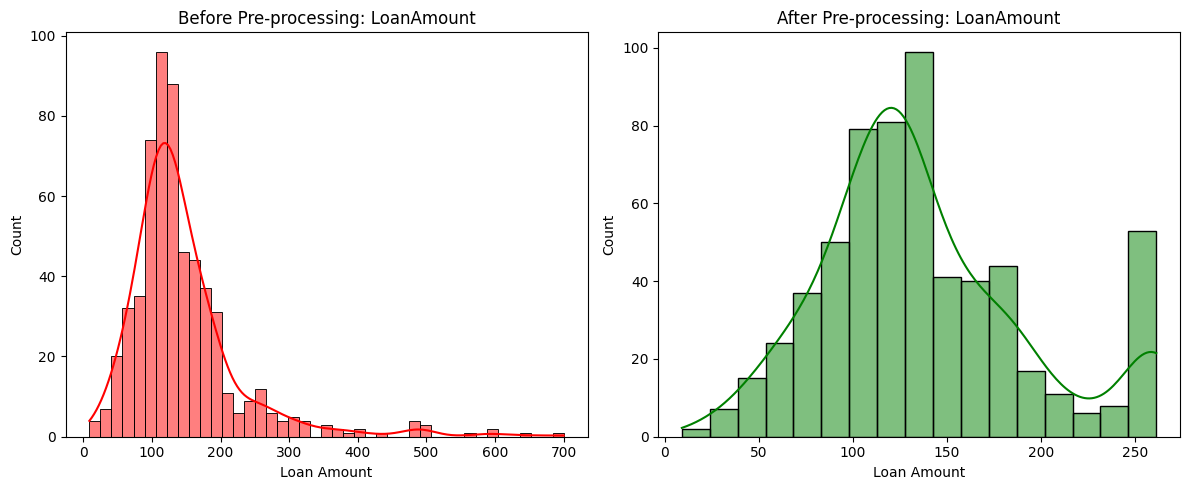

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

df_raw = pd.read_csv('/content/drive/My Drive/SEM 5/AIML LAB/Prediction_Data.csv')

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(df_raw['LoanAmount'].dropna(), kde=True, color='red', ax=axes[0])
axes[0].set_title('Before Pre-processing: LoanAmount')
axes[0].set_xlabel('Loan Amount')

sns.histplot(df['LoanAmount'], kde=True, color='green', ax=axes[1])
axes[1].set_title('After Pre-processing: LoanAmount')
axes[1].set_xlabel('Loan Amount')

plt.tight_layout()
plt.show()

#19

In [ ]:
output_path = '/content/drive/My Drive/SEM 5/AIML LAB/Cleaned_Prediction_Data.csv'
df.to_csv(output_path, index=False)

print(f"Dataset successfully saved to: {output_path}")

Dataset successfully saved to: /content/drive/My Drive/SEM 5/AIML LAB/Cleaned_Prediction_Data.csv


Mounted at /content/drive
=== LINEAR REGRESSION RESULTS ===
Regression Equation : LoanAmount = (0.0130 * ApplicantIncome) + 77.6320
Slope (m) : 0.0130
Intercept (c) : 77.6320
R² Score : 0.1716
Mean Squared Error : 2207.8085


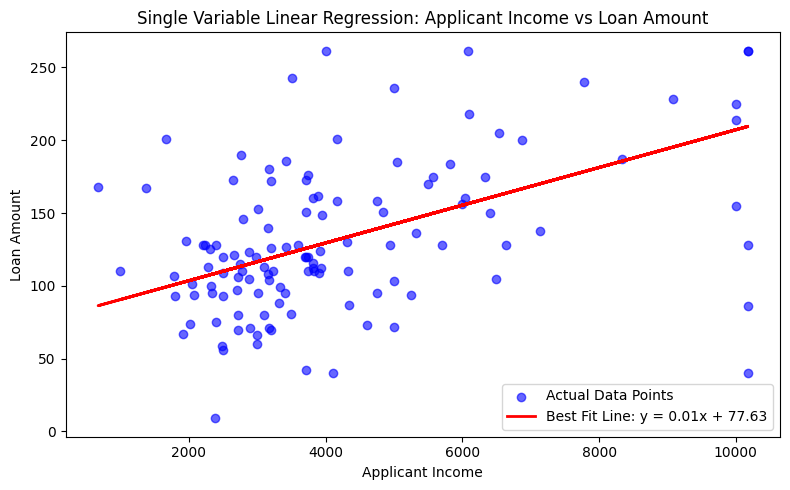

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from google.colab import drive


drive.mount('/content/drive')
file_path = '/content/drive/My Drive/SEM 5/AIML LAB/Prediction_Data.csv'
df = pd.read_csv(file_path)


df['ApplicantIncome'] = df['ApplicantIncome'].fillna(df['ApplicantIncome'].median())
df['LoanAmount'] = df['LoanAmount'].fillna(df['LoanAmount'].median())

for col in ['ApplicantIncome', 'LoanAmount']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    upper = Q3 + 1.5 * IQR
    lower = Q1 - 1.5 * IQR
    df[col] = np.where(df[col] > upper, upper, np.where(df[col] < lower, lower, df[col]))


X = df[['ApplicantIncome']]
y = df['LoanAmount']


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


model = LinearRegression()
model.fit(X_train, y_train)


y_pred = model.predict(X_test)


slope = model.coef_[0]
intercept = model.intercept_
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)

print("=== LINEAR REGRESSION RESULTS ===")
print(f"Regression Equation : LoanAmount = ({slope:.4f} * ApplicantIncome) + {intercept:.4f}")
print(f"Slope (m) : {slope:.4f}")
print(f"Intercept (c) : {intercept:.4f}")
print(f"R² Score : {r2:.4f}")
print(f"Mean Squared Error : {mse:.4f}")


plt.figure(figsize=(8, 5))
plt.scatter(X_test, y_test, color='blue', alpha=0.6, label='Actual Data Points')
plt.plot(X_test, y_pred, color='red', linewidth=2, label=f'Best Fit Line: y = {slope:.2f}x + {intercept:.2f}')
plt.title('Single Variable Linear Regression: Applicant Income vs Loan Amount')
plt.xlabel('Applicant Income')
plt.ylabel('Loan Amount')
plt.legend()
plt.tight_layout()
plt.show()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
=== MULTIVARIABLE LINEAR REGRESSION RESULTS ===
Feature Coefficients:
  - ApplicantIncome: 0.0149
  - CoapplicantIncome: 0.0138
Intercept (c) : 48.7000
R² Score : 0.3736
Mean Squared Error (MSE) : 1669.5672
Root Mean Squared Error (RMSE) : 40.8603


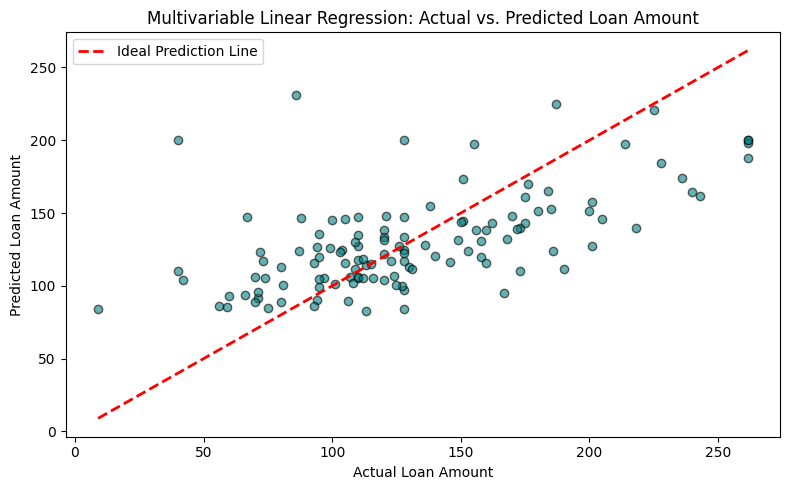

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from google.colab import drive

drive.mount('/content/drive')
file_path = '/content/drive/My Drive/SEM 5/AIML LAB/Prediction_Data.csv'
df = pd.read_csv(file_path)

num_cols = ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount']

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    upper = Q3 + 1.5 * IQR
    lower = Q1 - 1.5 * IQR
    df[col] = np.where(df[col] > upper, upper, np.where(df[col] < lower, lower, df[col]))

feature_cols = ['ApplicantIncome', 'CoapplicantIncome']
X = df[feature_cols]
y = df['LoanAmount']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

intercept = model.intercept_
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("=== MULTIVARIABLE LINEAR REGRESSION RESULTS ===")
print("Feature Coefficients:")
for col, coef in zip(feature_cols, model.coef_):
    print(f"  - {col}: {coef:.4f}")
print(f"Intercept (c) : {intercept:.4f}")
print(f"R² Score : {r2:.4f}")
print(f"Mean Squared Error (MSE) : {mse:.4f}")
print(f"Root Mean Squared Error (RMSE) : {rmse:.4f}")

plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, color='teal', alpha=0.6, edgecolors='k')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--', linewidth=2, label='Ideal Prediction Line')
plt.title('Multivariable Linear Regression: Actual vs. Predicted Loan Amount')
plt.xlabel('Actual Loan Amount')
plt.ylabel('Predicted Loan Amount')
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
import heapq

def greedy_best_first_search(graph, start, goal, heuristics):
    open_set = []
    heapq.heappush(open_set, (heuristics[start], start, [start]))

    visited = set()

    while open_set:

        current_h, current_node, path = heapq.heappop(open_set)

        if current_node == goal:
            return path

        if current_node in visited:
            continue

        visited.add(current_node)

        for neighbor in graph.get(current_node, []):
            if neighbor not in visited:
                heapq.heappush(
                    open_set,
                    (heuristics[neighbor], neighbor, path + [neighbor])
                )

    return None



graph = {
    'S': ['A', 'B'],
    'A': ['C', 'D'],
    'B': ['E', 'F'],
    'C': [],
    'D': ['G'],
    'E': [],
    'F': ['G'],
    'G': []
}

heuristics = {
    'S': 7,
    'A': 6,
    'B': 2,
    'C': 5,
    'D': 1,
    'E': 3,
    'F': 1,
    'G': 0
}

start_node, goal_node = 'S', 'G'
path = greedy_best_first_search(graph, start_node, goal_node, heuristics)

print(f"Path found from {start_node} to {goal_node}: {path}")

Path found from S to G: ['S', 'B', 'F', 'G']


In [ ]:
import heapq

def a_star_search(graph, start, goal, heuristics):
    open_set = []
    heapq.heappush(open_set, (heuristics[start], 0, start, [start]))

    g_scores = {start: 0}

    while open_set:
        f_score, g_score, current_node, path = heapq.heappop(open_set)

        if current_node == goal:
            return path, g_score

        if g_score > g_scores.get(current_node, float('inf')):
            continue

        for neighbor, edge_cost in graph.get(current_node, []):
            tentative_g = g_score + edge_cost

            if tentative_g < g_scores.get(neighbor, float('inf')):
                g_scores[neighbor] = tentative_g
                f_score = tentative_g + heuristics[neighbor]
                heapq.heappush(
                    open_set,
                    (f_score, tentative_g, neighbor, path + [neighbor])
                )

    return None, float('inf')

if __name__ == "__main__":
    graph = {
        'S': [('A', 1), ('B', 5)],
        'A': [('G', 2)],
        'B': [('G', 10)],
        'G': []
    }

    heuristics = {
        'S': 10,
        'A': 10,
        'B': 2,
        'G': 0
    }

    start_node = 'S'
    goal_node = 'G'

    path, total_cost = a_star_search(graph, start_node, goal_node, heuristics)

    print("========================================")
    print("          A* SEARCH RESULTS             ")
    print("========================================")
    print(f"Start Node : {start_node}")
    print(f"Goal Node  : {goal_node}")
    print(f"Path Found : {' -> '.join(path) if path else 'No path found'}")
    print(f"Total Cost : {total_cost}")
    print("========================================")

          A* SEARCH RESULTS             
Start Node : S
Goal Node  : G
Path Found : S -> A -> G
Total Cost : 3


In [ ]:
import heapq

def uniform_cost_search(graph, start, goal):
    open_set = []
    heapq.heappush(open_set, (0, start, [start]))

    visited = set()

    while open_set:
        g_cost, current_node, path = heapq.heappop(open_set)

        if current_node == goal:
            return path, g_cost

        if current_node in visited:
            continue

        visited.add(current_node)

        for neighbor, edge_cost in graph.get(current_node, []):
            if neighbor not in visited:
                total_g = g_cost + edge_cost
                heapq.heappush(
                    open_set,
                    (total_g, neighbor, path + [neighbor])
                )

    return None, float('inf')


if __name__ == "__main__":
    graph = {
        'S': [('A', 2), ('B', 5)],
        'A': [('B', 1), ('C', 4)],
        'B': [('G', 6)],
        'C': [('G', 1)],
        'G': []
    }

    path, total_cost = uniform_cost_search(graph, 'S', 'G')

    print(f"Optimal Path : {' -> '.join(path)}")
    print(f"Total Cost   : {total_cost}")


Optimal Path : S -> A -> C -> G
Total Cost   : 7


In [ ]:

graph = {
    'A': ['B', 'C'],
    'B': ['D', 'E'],
    'C': ['F'],
    'D': [],
    'E': ['F'],
    'F': []
}

In [ ]:
from collections import deque

def bfs(graph, start_node):
    visited = set()
    queue = deque([start_node])
    visited.add(start_node)

    result = []

    while queue:
        node = queue.popleft()
        result.append(node)

        for neighbor in graph[node]:
            if neighbor not in visited:
                visited.add(neighbor)
                queue.append(neighbor)

    return result

graph = {
    'S': ['A', 'B'],
    'A': ['C', 'D'],
    'B': ['E', 'F'],
    'C': [],
    'D': ['G'],
    'E': [],
    'F': ['G'],
    'G': []
}
print("BFS Traversal:", bfs(graph, 'A'))

In [ ]:
def dfs_iterative(graph, start_node):
    visited = set()
    stack = [start_node]
    result = []

    while stack:
        node = stack.pop()
        if node not in visited:
            visited.add(node)
            result.append(node)

            for neighbor in reversed(graph[node]):
                if neighbor not in visited:
                    stack.append(neighbor)

    return result

print("DFS Iterative:", dfs_iterative(graph, 'A'))

DFS Iterative: ['A', 'B', 'D', 'E', 'F', 'C']


In [ ]:
#DECISION TREE _ CLASSIFIER

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

X, y = make_classification(
    n_samples=1000,
    n_features=10,
    n_informative=8,
    n_redundant=0,
    n_classes=2,
    class_sep=1.5,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=5,
    min_samples_split=2,
    random_state=42
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)


print("--- Decision Tree Classifier ---")
print(f"Accuracy: {accuracy_score(y_test, predictions) * 100:.2f}%")
print(f"F1 Score: {f1_score(y_test, predictions, average='weighted'):.4f}\n")
print(classification_report(y_test, predictions))

--- Decision Tree Classifier ---
Accuracy: 82.00%
F1 Score: 0.8195

              precision    recall  f1-score   support

           0       0.86      0.77      0.81       100
           1       0.79      0.87      0.83       100

    accuracy                           0.82       200
   macro avg       0.82      0.82      0.82       200
weighted avg       0.82      0.82      0.82       200



In [ ]:
#RANDOM FOREST CLASSIFIER

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

X, y = make_classification(
    n_samples=1000,
    n_features=10,
    n_informative=8,
    n_redundant=0,
    n_classes=2,
    class_sep=1.5,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = RandomForestClassifier(
    n_estimators=100,
    max_depth=8,
    random_state=42
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("--- Random Forest Classifier ---")
print(f"Accuracy: {accuracy_score(y_test, predictions) * 100:.2f}%")
print(f"F1 Score: {f1_score(y_test, predictions, average='weighted'):.4f}\n")
print(classification_report(y_test, predictions))

--- Random Forest Classifier ---
Accuracy: 92.00%
F1 Score: 0.9199

              precision    recall  f1-score   support

           0       0.95      0.89      0.92       100
           1       0.90      0.95      0.92       100

    accuracy                           0.92       200
   macro avg       0.92      0.92      0.92       200
weighted avg       0.92      0.92      0.92       200



In [ ]:
#SUPPORT VECTOR CLASSIFIER

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, classification_report

X, y = make_classification(
    n_samples=1000,
    n_features=10,
    n_informative=8,
    n_redundant=0,
    n_classes=2,
    class_sep=1.5,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = SVC(
    kernel='rbf',
    C=1.0,
    gamma='scale',
    probability=True,
    random_state=42
)

model.fit(X_train_scaled, y_train)

predictions = model.predict(X_test_scaled)

print("--- Support Vector Classifier (SVC) ---")
print(f"Accuracy: {accuracy_score(y_test, predictions) * 100:.2f}%")
print(f"F1 Score: {f1_score(y_test, predictions, average='weighted'):.4f}\n")
print(classification_report(y_test, predictions))

--- Support Vector Classifier (SVC) ---
Accuracy: 93.00%
F1 Score: 0.9299

              precision    recall  f1-score   support

           0       0.97      0.89      0.93       100
           1       0.90      0.97      0.93       100

    accuracy                           0.93       200
   macro avg       0.93      0.93      0.93       200
weighted avg       0.93      0.93      0.93       200



In [ ]:
#DECISION TREE REGRESSOR

from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score

X, y = make_regression(
    n_samples=1000,
    n_features=10,
    n_informative=8,
    noise=5.0,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

model = DecisionTreeRegressor(
    criterion='squared_error',
    max_depth=10,
    min_samples_split=2,
    min_samples_leaf=2,
    random_state=42
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("--- Decision Tree Regressor ---")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, predictions):.2f}")
print(f"R² Score:                 {r2_score(y_test, predictions):.4f}")

--- Decision Tree Regressor ---
Mean Squared Error (MSE): 2601.25
R² Score:                 0.7905


In [ ]:
#RANDOM FOREST REGRESSOR

from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

X, y = make_regression(
    n_samples=1000,
    n_features=10,
    n_informative=8,
    noise=15.0,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

model = RandomForestRegressor(
    n_estimators=300,
    max_depth=12,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features=1.0,
    random_state=42,
    n_jobs=-1
)


model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("--- Random Forest Regressor ---")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, predictions):.2f}")
print(f"R² Score:                 {r2_score(y_test, predictions):.4f}")

--- Random Forest Regressor ---
Mean Squared Error (MSE): 1514.71
R² Score:                 0.8787


In [ ]:
#SUPPORT VECTOR REGRESSOR

from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, r2_score

X, y = make_regression(
    n_samples=1000,
    n_features=10,
    n_informative=8,
    noise=15.0,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = SVR(
    kernel='rbf',
    C=1000.0,
    gamma='scale',
    epsilon=0.1
)

model.fit(X_train_scaled, y_train)

predictions = model.predict(X_test_scaled)

print("--- Support Vector Regressor (SVR) ---")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, predictions):.2f}")
print(f"R² Score:                 {r2_score(y_test, predictions):.4f}")

--- Support Vector Regressor (SVR) ---
Mean Squared Error (MSE): 713.19
R² Score:                 0.9429


In [ ]:
#LOGISTIC REGRESSION


import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# 1. Generate Synthetic Binary Dataset
X, y = make_classification(
    n_samples=1000,
    n_features=10,
    n_informative=8,
    n_redundant=0,
    n_classes=2,
    class_sep=1.5,
    random_state=42
)

# 2. Stratified Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 3. Model Initialization & Training
model = LogisticRegression(random_state=42)
model.fit(X_train, y_train)

# 4. Predictions (Class Labels & Probabilities)
y_pred = model.predict(X_test)
y_probs = model.predict_proba(X_test)[:, 1]  # Probability of belonging to Class 1

# 5. Model Evaluation Metrics
print("--- Logistic Regression Classifier ---")
print(f"Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%")
print(f"F1 Score: {f1_score(y_test, y_pred, average='weighted'):.4f}\n")
print(classification_report(y_test, y_pred))

# 6. Confusion Matrix Visualization
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - Logistic Regression')
plt.tight_layout()
plt.show()

--- Neural Network (MLP) Classifier ---
Accuracy: 93.50%
F1 Score: 0.9350

              precision    recall  f1-score   support

           0       0.94      0.93      0.93       100
           1       0.93      0.94      0.94       100

    accuracy                           0.94       200
   macro avg       0.94      0.94      0.93       200
weighted avg       0.94      0.94      0.93       200



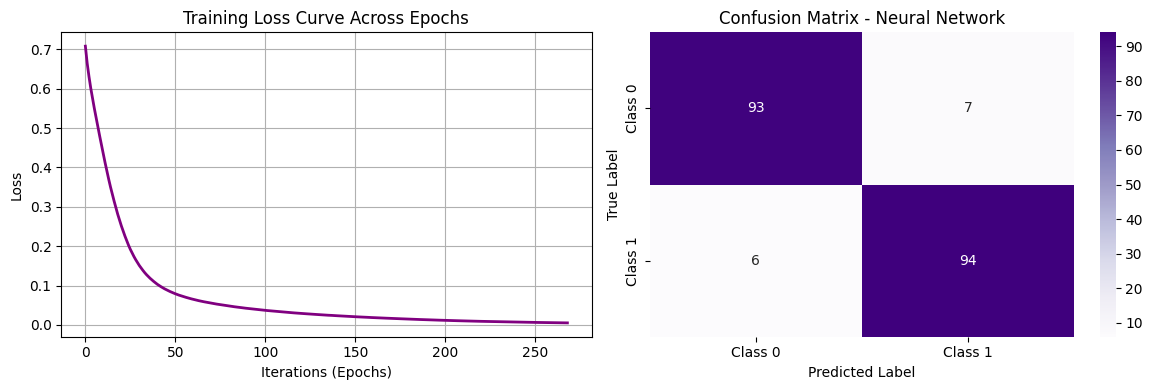

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# 1. Generate Synthetic Binary Dataset
X, y = make_classification(
    n_samples=1000,
    n_features=10,
    n_informative=8,
    n_redundant=0,
    n_classes=2,
    class_sep=1.5,
    random_state=42
)

# 2. Stratified Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 3. Feature Scaling (Essential for Neural Networks)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Model Initialization & Training
model = MLPClassifier(
    hidden_layer_sizes=(64, 32),  # Two hidden layers: 64 neurons, then 32 neurons
    activation='relu',            # Rectified Linear Unit activation
    solver='adam',                # Optimizer for weight updates
    max_iter=500,                 # Maximum training epochs
    random_state=42
)
model.fit(X_train_scaled, y_train)

# 5. Model Evaluation
y_pred = model.predict(X_test_scaled)

print("--- Neural Network (MLP) Classifier ---")
print(f"Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%")
print(f"F1 Score: {f1_score(y_test, y_pred, average='weighted'):.4f}\n")
print(classification_report(y_test, y_pred))

# 6. Loss Curve & Confusion Matrix Visualization
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Training Loss Curve
axes[0].plot(model.loss_curve_, color='purple', linewidth=2)
axes[0].set_title('Training Loss Curve Across Epochs')
axes[0].set_xlabel('Iterations (Epochs)')
axes[0].set_ylabel('Loss')
axes[0].grid(True)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', ax=axes[1],
            xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'])
axes[1].set_title('Confusion Matrix - Neural Network')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

plt.tight_layout()
plt.show()

In [ ]:
# 1. (Optional) Mount Drive if your files are inside a Google Drive folder
from google.colab import drive
drive.mount('/content/drive')

# 2. Navigate to your project folder (adjust the path to match where your files are stored)
%cd /content/drive/MyDrive/Your_Folder_Name

# 3. Configure Git credentials
!git config --global user.name "k-v-n25"
!git config --global user.email "240233@tkmce.ac.in"

# 4. Initialize Git repository and add files
!git init
!git add .
!git commit -m "Initial upload of AI/ML codes"
!git branch -M main

# 5. Push to your repository using a Personal Access Token (PAT)
# Replace YOUR_GITHUB_TOKEN with your actual token
!git remote add origin https://YOUR_GITHUB_TOKEN@github.com/k-v-n25/ML-AI.git
!git push -u origin main --force